# Miami House Price Prediction

Predicting single-family home **sale prices** in Miami-Dade County using regression models in Python (pandas, scikit-learn).

**Workflow:** data inspection → exploratory analysis → preprocessing → model comparison (cross-validation) → hyperparameter tuning → test-set evaluation → feature importance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/miami-housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (13932, 17)


,LATITUDE,LONGITUDE,PARCELNO,SALE_PRC,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality
0,25.891031,-80.160561,622280070620,440000.0,9375,1753,0,2815.9,12811.4,347.6,42815.3,37742.2,15954.9,67,0,8,4
1,25.891324,-80.153968,622280100460,349000.0,9375,1715,0,4359.1,10648.4,337.8,43504.9,37340.5,18125.0,63,0,9,4
2,25.891334,-80.153740,622280100470,800000.0,9375,2276,49206,4412.9,10574.1,297.1,43530.4,37328.7,18200.5,61,0,2,4
3,25.891765,-80.152657,622280100530,988000.0,12450,2058,10033,4585.0,10156.5,0.0,43797.5,37423.2,18514.4,63,0,9,4
4,25.891825,-80.154639,622280100200,755000.0,12800,1684,16681,4063.4,10836.8,326.6,43599.7,37550.8,17903.4,42,0,7,4


In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("PARCELNO unique values:", df["PARCELNO"].nunique(), "of", len(df))
df.describe().T

Missing values: 0
Duplicate rows: 0
PARCELNO unique values: 13776 of 13932


,count,mean,std,min,25%,50%,75%,max
LATITUDE,13932.0,2.572881e+01,1.406333e-01,2.543433e+01,2.562006e+01,2.573181e+01,2.585227e+01,2.597438e+01
LONGITUDE,13932.0,-8.032748e+01,8.919907e-02,-8.054217e+01,-8.040328e+01,-8.033891e+01,-8.025802e+01,-8.011975e+01
PARCELNO,13932.0,2.356496e+12,1.199290e+12,1.020008e+11,1.079160e+12,3.040300e+12,3.060170e+12,3.660170e+12
SALE_PRC,13932.0,3.999419e+05,3.172147e+05,7.200000e+04,2.350000e+05,3.100000e+05,4.280000e+05,2.650000e+06
LND_SQFOOT,13932.0,8.620880e+03,6.070089e+03,1.248000e+03,5.400000e+03,7.500000e+03,9.126250e+03,5.706400e+04
TOT_LVG_AREA,13932.0,2.058045e+03,8.135385e+02,8.540000e+02,1.470000e+03,1.877500e+03,2.471000e+03,6.287000e+03
SPEC_FEAT_VAL,13932.0,9.562493e+03,1.389097e+04,0.000000e+00,8.100000e+02,2.765500e+03,1.235225e+04,1.750200e+05
RAIL_DIST,13932.0,8.348549e+03,6.178027e+03,1.050000e+01,3.299450e+03,7.106300e+03,1.210260e+04,2.962150e+04
OCEAN_DIST,13932.0,3.169099e+04,1.759508e+04,2.361000e+02,1.807935e+04,2.854175e+04,4.431065e+04,7.574490e+04
WATER_DIST,13932.0,1.196029e+04,1.193299e+04,0.000000e+00,2.675850e+03,6.922600e+03,1.920000e+04,5.039980e+04


**Column notes**

| Column | Meaning |
|---|---|
| `SALE_PRC` | Sale price in USD (**target**) |
| `LND_SQFOOT` | Land area (sq ft) |
| `TOT_LVG_AREA` | Floor area (sq ft) |
| `SPEC_FEAT_VAL` | Value of special features (e.g. pools) |
| `RAIL_DIST`, `OCEAN_DIST`, `WATER_DIST`, `CNTR_DIST`, `SUBCNTR_DI`, `HWY_DIST` | Distances (ft) to rail, ocean, nearest water body, Miami central business district, nearest subcenter, nearest highway |
| `age` | Age of the structure (years) |
| `avno60plus` | 1 if airplane noise exceeds an acceptable level |
| `month_sold` | Month of sale (1 = January) |
| `structure_quality` | Quality of the structure (1 to 5) |
| `LATITUDE`, `LONGITUDE` | Location coordinates |
| `PARCELNO` | Parcel identifier (not a predictive feature) |

## 2. Exploratory data analysis

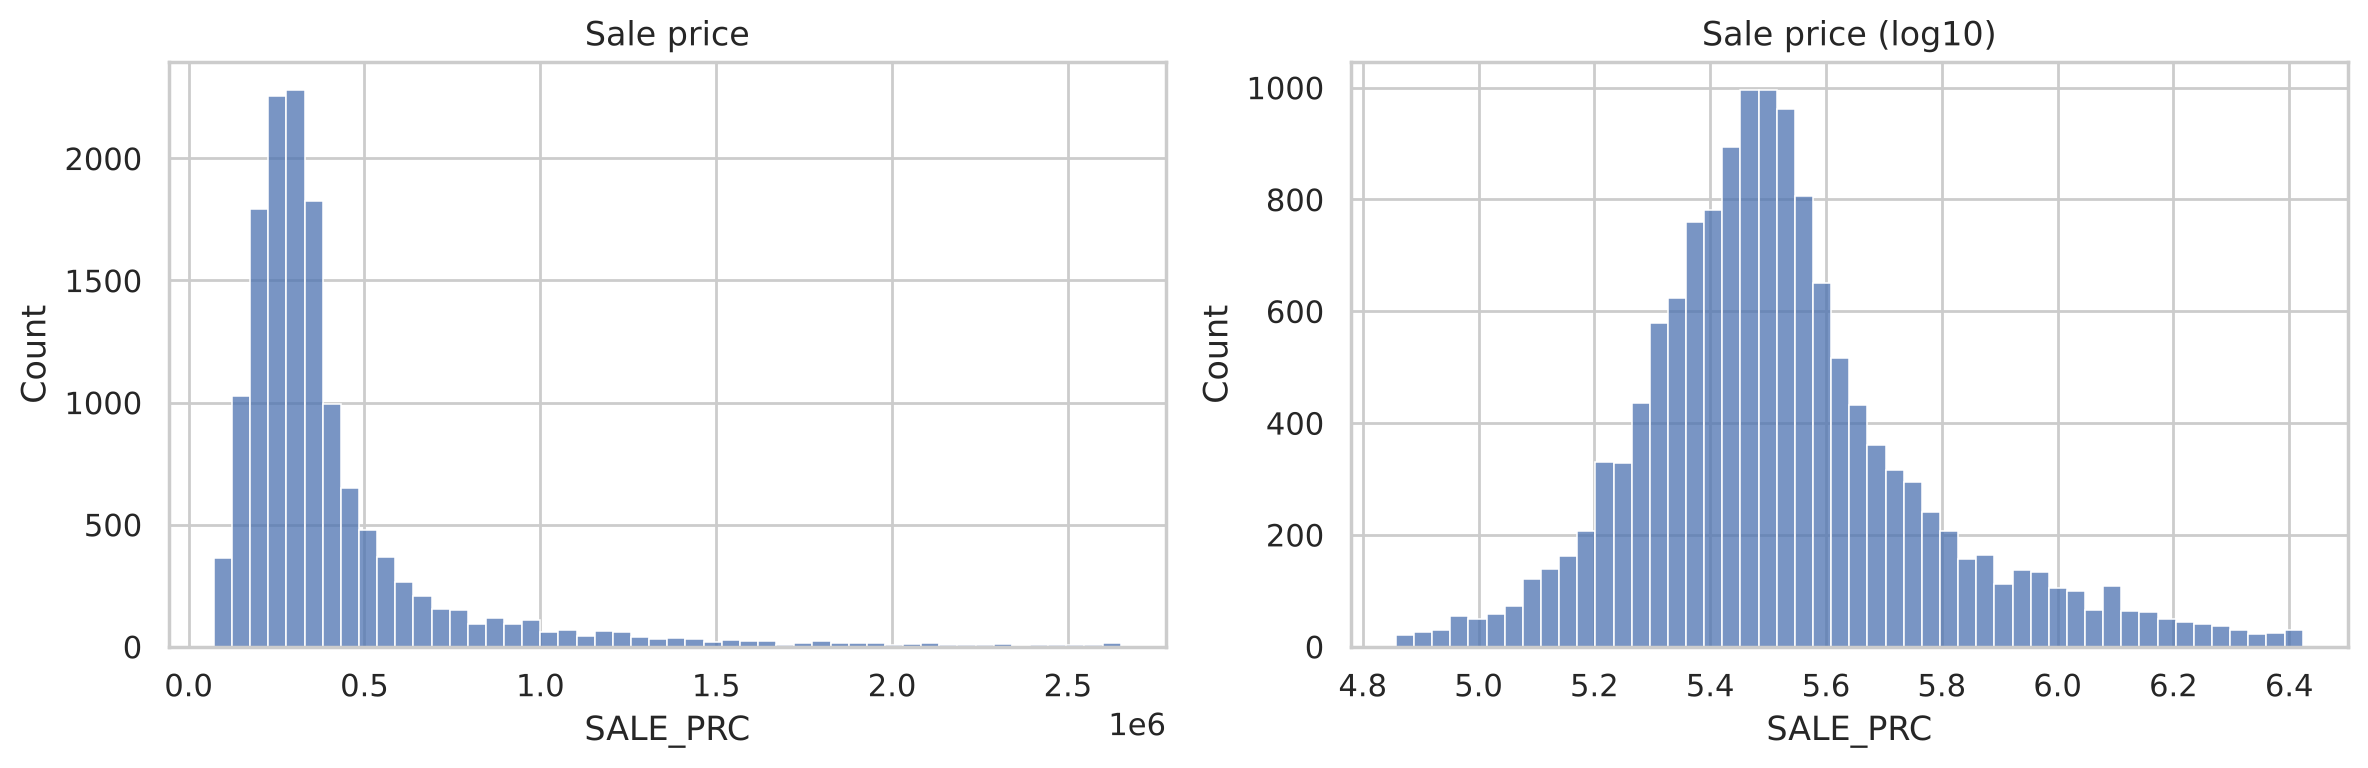

Skewness of SALE_PRC: 3.22


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SALE_PRC"], bins=50, ax=axes[0])
axes[0].set_title("Sale price")
sns.histplot(np.log10(df["SALE_PRC"]), bins=50, ax=axes[1])
axes[1].set_title("Sale price (log10)")
plt.tight_layout()
plt.savefig("images/price_distribution.png", dpi=150)
plt.show()
print("Skewness of SALE_PRC:", round(df["SALE_PRC"].skew(), 2))

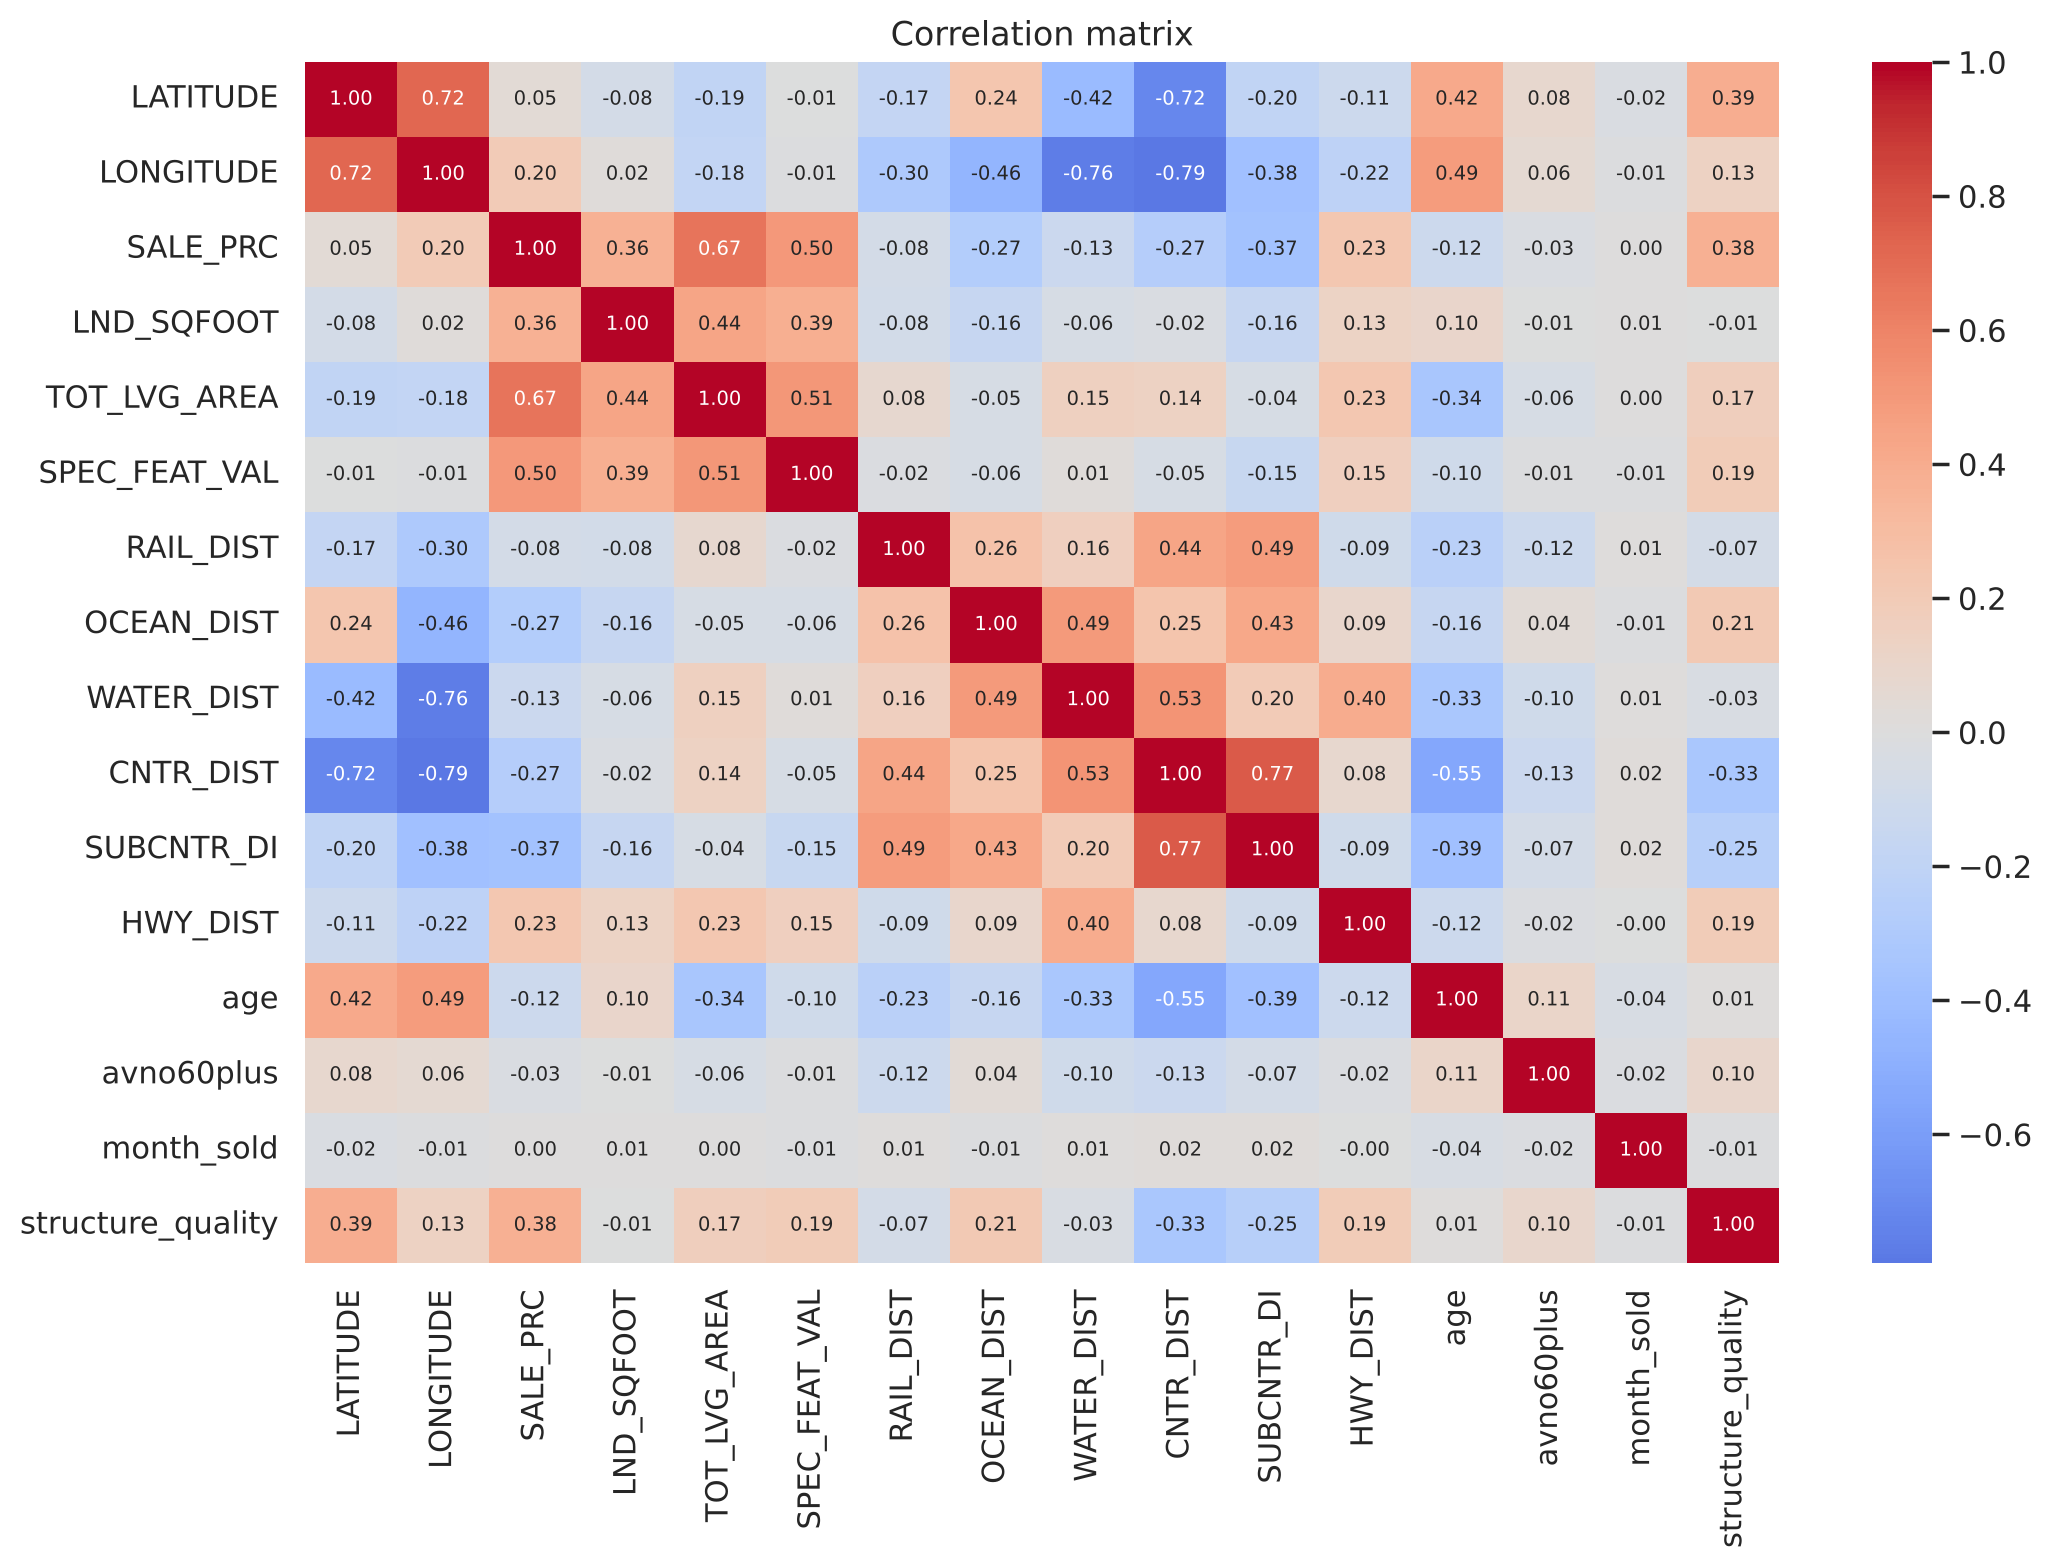

Correlation with SALE_PRC:
TOT_LVG_AREA         0.667
SPEC_FEAT_VAL        0.497
structure_quality    0.384
LND_SQFOOT           0.363
HWY_DIST             0.232
LONGITUDE            0.195
LATITUDE             0.048
month_sold           0.000
avno60plus          -0.027
RAIL_DIST           -0.077
age                 -0.123
WATER_DIST          -0.128
CNTR_DIST           -0.271
OCEAN_DIST          -0.275
SUBCNTR_DI          -0.370
Name: SALE_PRC, dtype: float64


In [5]:
corr = df.drop(columns=["PARCELNO"]).corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation with SALE_PRC:")
print(corr["SALE_PRC"].drop("SALE_PRC").sort_values(ascending=False).round(3))

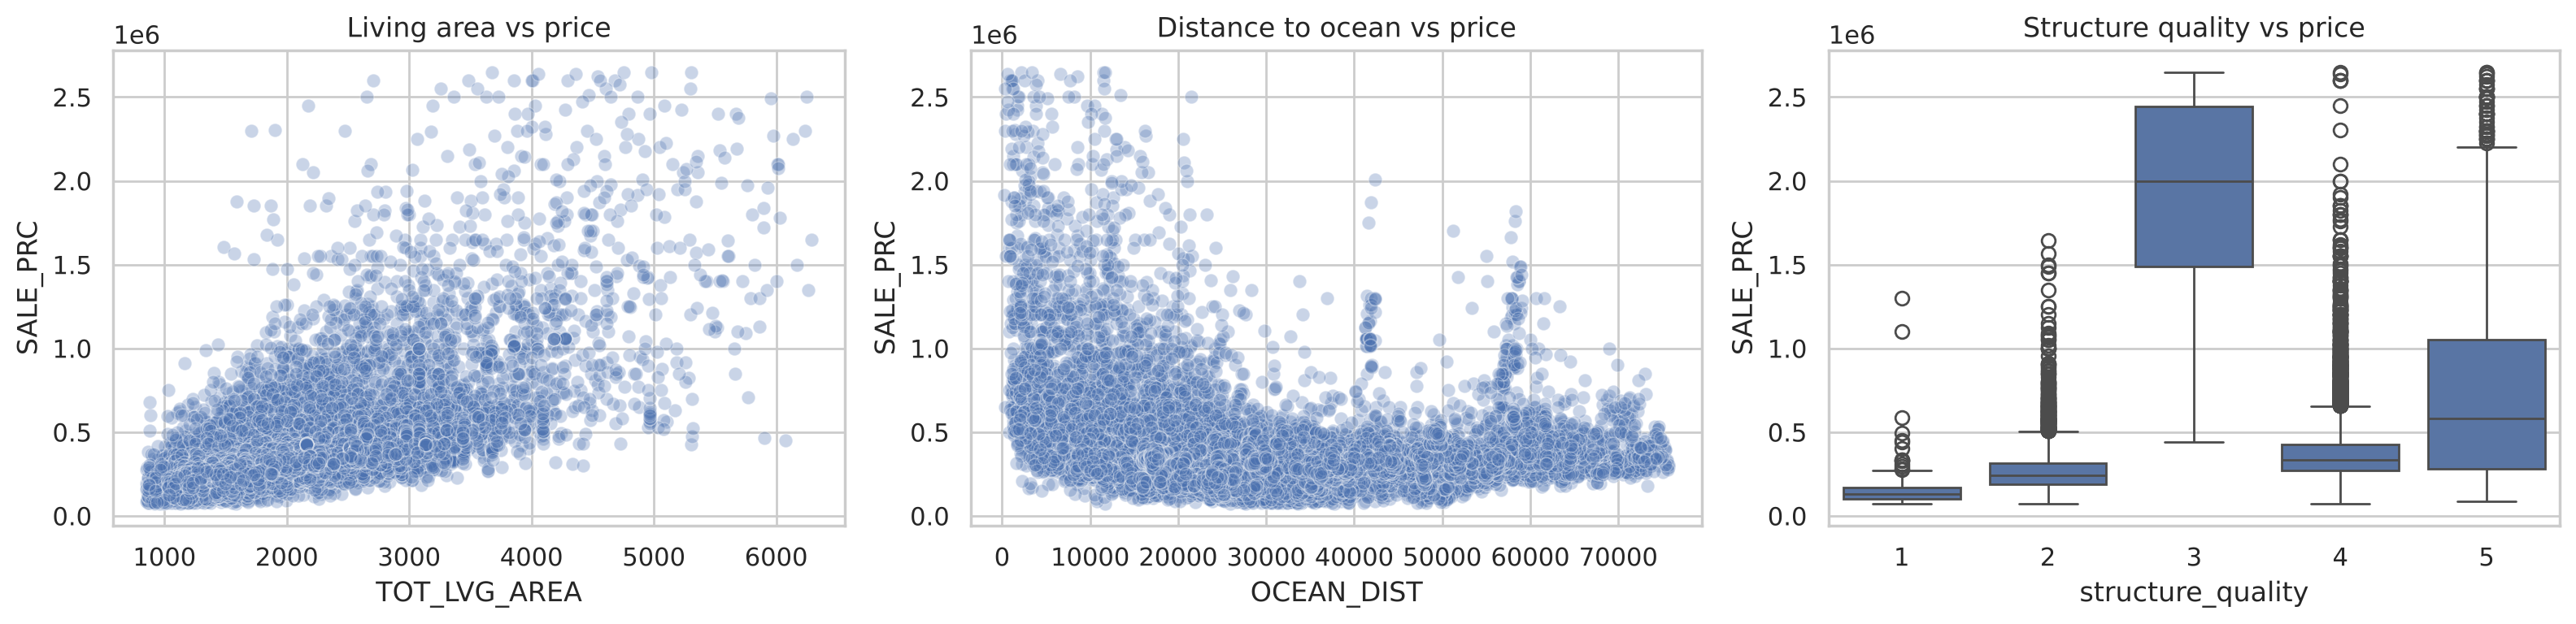

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="TOT_LVG_AREA", y="SALE_PRC", alpha=0.3, ax=axes[0])
axes[0].set_title("Living area vs price")
sns.scatterplot(data=df, x="OCEAN_DIST", y="SALE_PRC", alpha=0.3, ax=axes[1])
axes[1].set_title("Distance to ocean vs price")
sns.boxplot(data=df, x="structure_quality", y="SALE_PRC", ax=axes[2])
axes[2].set_title("Structure quality vs price")
plt.tight_layout()
plt.savefig("images/key_relationships.png", dpi=150)
plt.show()

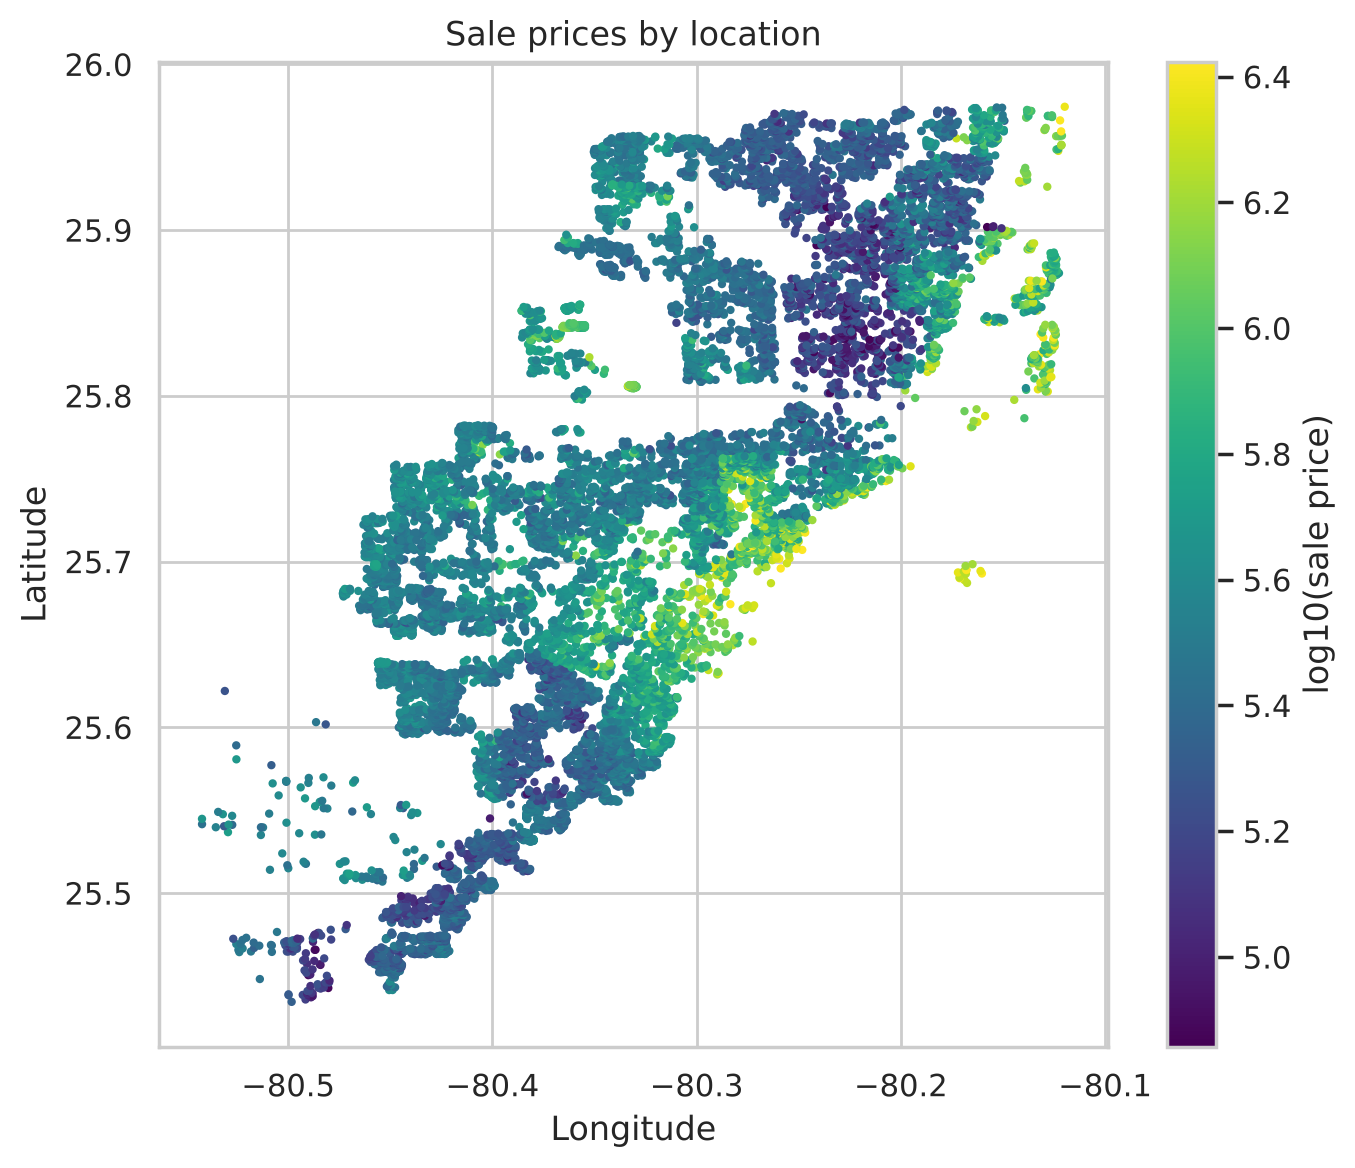

In [7]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(df["LONGITUDE"], df["LATITUDE"], c=np.log10(df["SALE_PRC"]), cmap="viridis", s=4)
plt.colorbar(sc, label="log10(sale price)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Sale prices by location")
plt.tight_layout()
plt.savefig("images/price_map.png", dpi=150)
plt.show()

## 3. Preprocessing

- `PARCELNO` is an identifier, so it is dropped.
- All remaining columns are numeric with no missing values, so no imputation or encoding is needed.
- 80/20 train-test split. The test set is not touched until the final evaluation.
- Scaling is placed **inside a pipeline** for the linear models, so it is fit on training folds only (no data leakage). Tree-based models do not need scaling.

In [8]:
X = df.drop(columns=["SALE_PRC", "PARCELNO"])
y = df["SALE_PRC"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (11145, 15) | Test: (2787, 15)


## 4. Model comparison (5-fold cross-validation on the training set)

Models range from simple and interpretable (linear) to flexible (ensembles).

In [9]:
models = {
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, n_jobs=1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    cv = cross_validate(
        model, X_train, y_train, cv=5,
        scoring=("neg_root_mean_squared_error", "r2"), n_jobs=1
    )
    rows.append({
        "Model": name,
        "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "CV RMSE std": cv["test_neg_root_mean_squared_error"].std(),
        "CV R2": cv["test_r2"].mean(),
    })

cv_results = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
cv_results.round(3)

,Model,CV RMSE,CV RMSE std,CV R2
0,Gradient Boosting,94281.930,8364.136,0.912
1,Random Forest,98235.621,12053.422,0.904
2,Decision Tree,136600.121,10939.905,0.814
3,Ridge,174988.031,10540.688,0.697
4,Linear Regression,174988.947,10536.845,0.697


## 5. Hyperparameter tuning (Random Forest)

A small grid search on the training set only, using 3-fold cross-validation.

In [10]:
param_grid = {
    "n_estimators": [100],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 3],
}
grid = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    param_grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=1
)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV RMSE:", round(-grid.best_score_, 1))
best_rf = grid.best_estimator_

Best params: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV RMSE: 98995.8


## 6. Final evaluation on the held-out test set

Every model is refit on the full training set and evaluated once on the test set. The tuned Random Forest replaces the default one.

In [11]:
final_models = {k: v for k, v in models.items() if k != "Random Forest"}
final_models["Random Forest (tuned)"] = best_rf

results = []
preds = {}
for name, model in final_models.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p),
        "R2": r2_score(y_test, p),
    })

test_results = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
test_results.round(3)

,Model,RMSE,MAE,R2
0,Gradient Boosting,89840.656,49294.050,0.918
1,Random Forest (tuned),98959.816,48643.983,0.901
2,Decision Tree,128623.099,67078.866,0.832
3,Ridge,174798.508,117311.708,0.690
4,Linear Regression,174805.273,117327.554,0.690


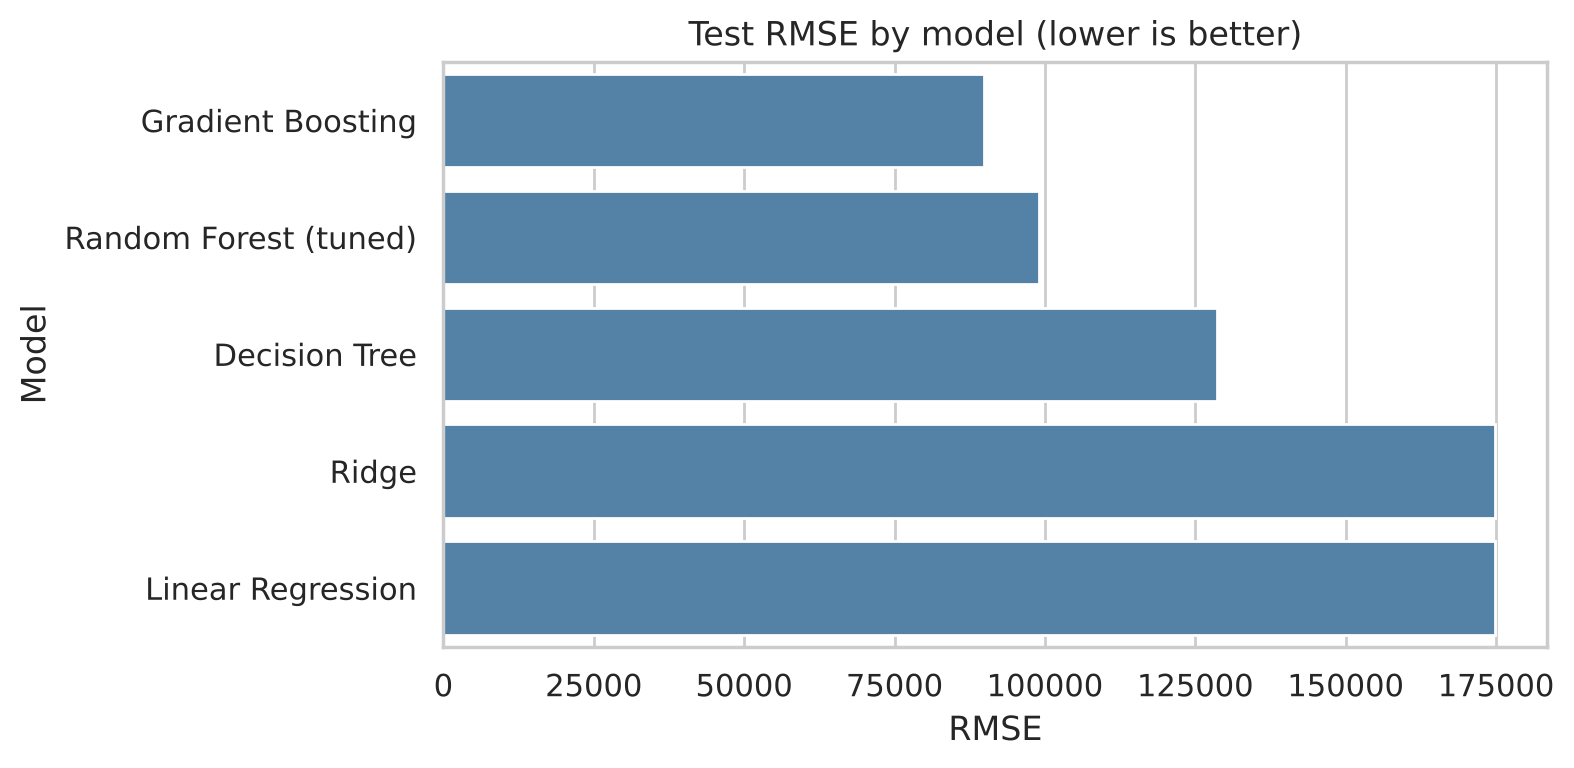

In [12]:
plt.figure(figsize=(8, 4))
sns.barplot(data=test_results, y="Model", x="RMSE", color="steelblue")
plt.title("Test RMSE by model (lower is better)")
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150)
plt.show()

## 7. Predictions vs actual (best model)

Best model on test set: Gradient Boosting


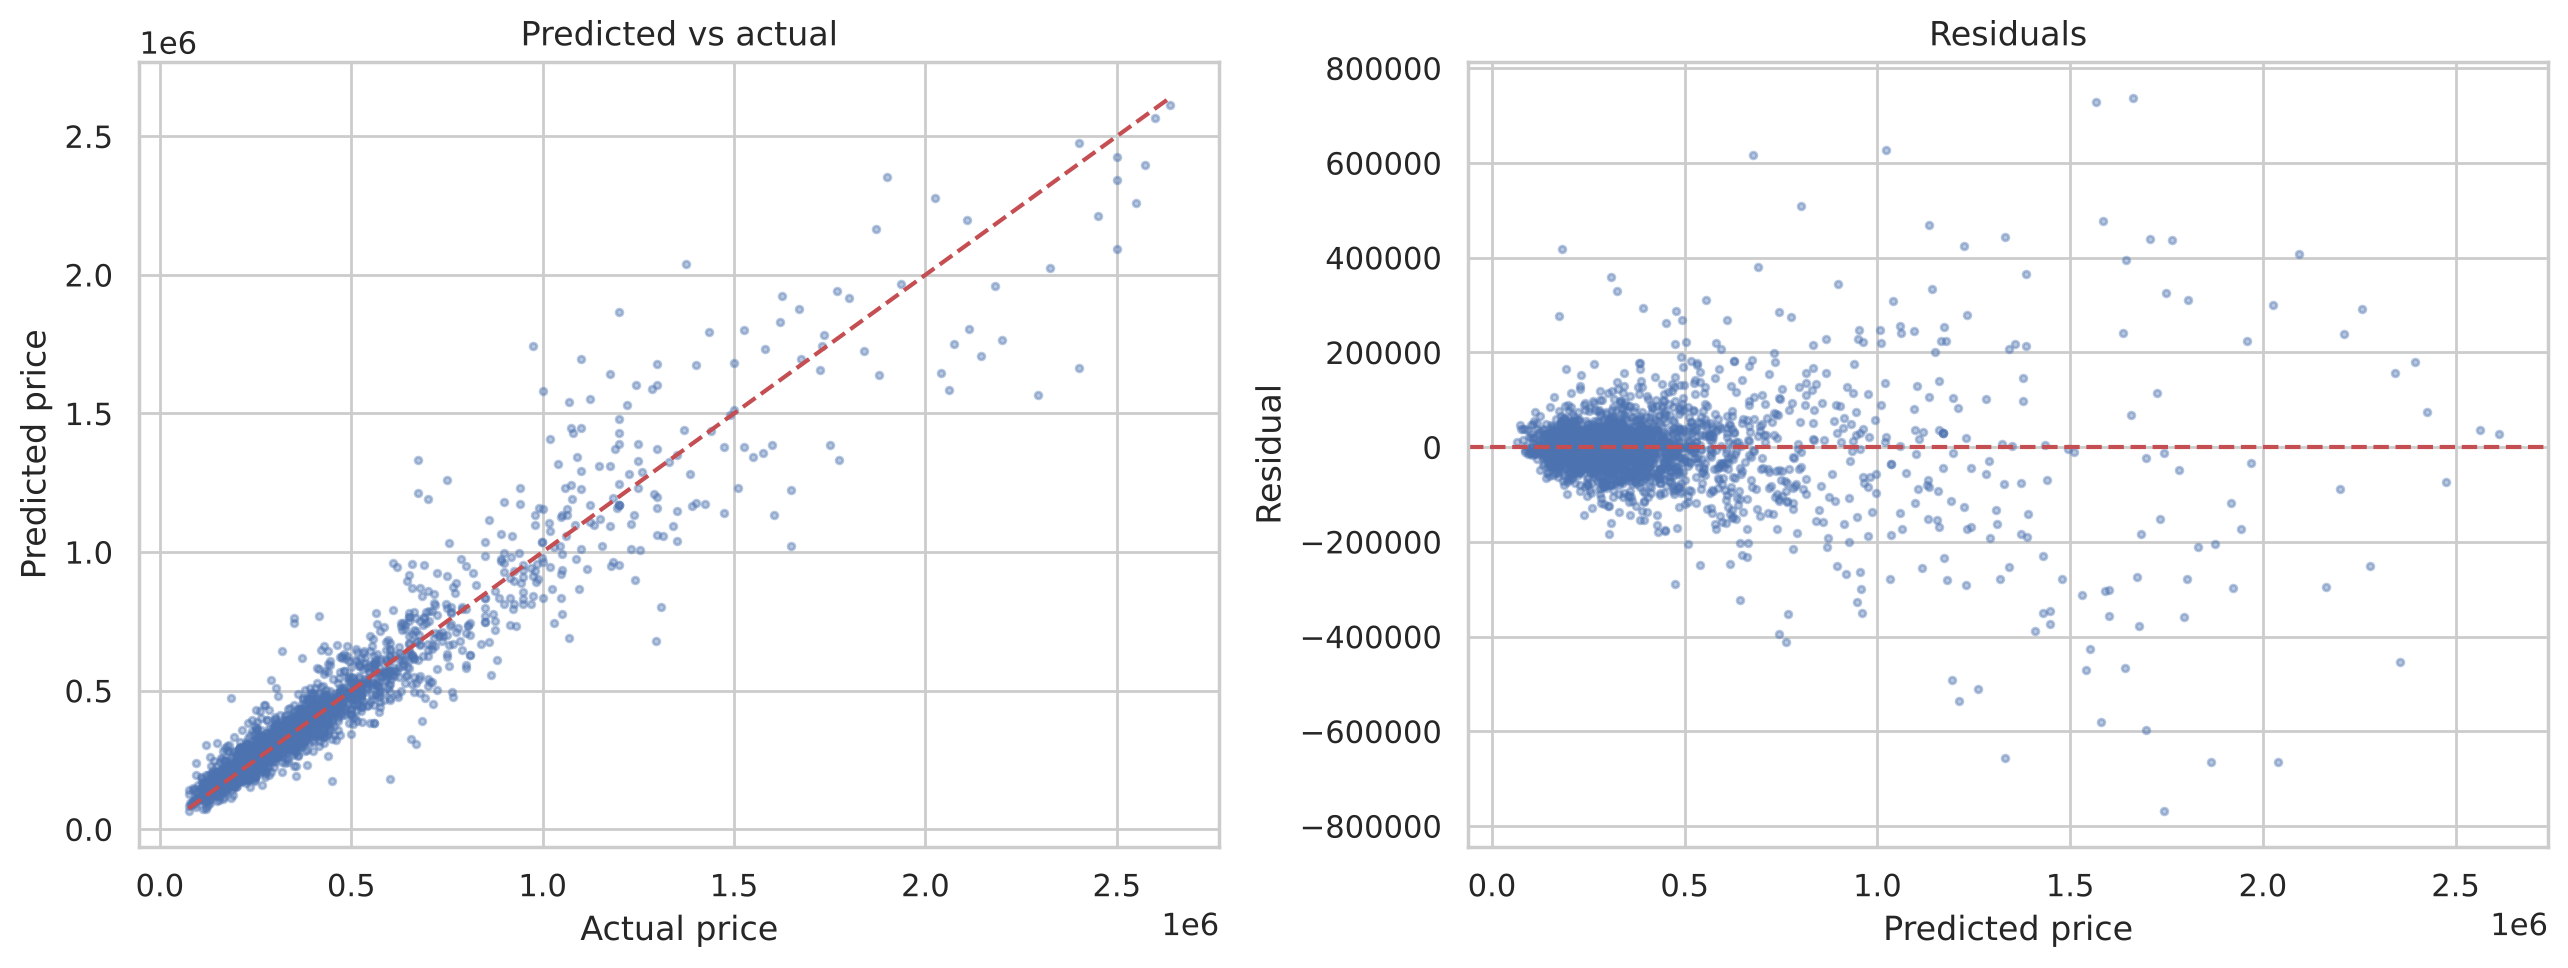

Mean absolute percentage error: 12.3%


In [13]:
best_name = test_results.loc[0, "Model"]
best_pred = preds[best_name]
print("Best model on test set:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, best_pred, s=6, alpha=0.4)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Predicted vs actual")

residuals = y_test - best_pred
axes[1].scatter(best_pred, residuals, s=6, alpha=0.4)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted price"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals")
plt.tight_layout()
plt.savefig("images/predictions_residuals.png", dpi=150)
plt.show()

mape = (np.abs(residuals) / y_test).mean() * 100
print(f"Mean absolute percentage error: {mape:.1f}%")

## 8. Feature importance

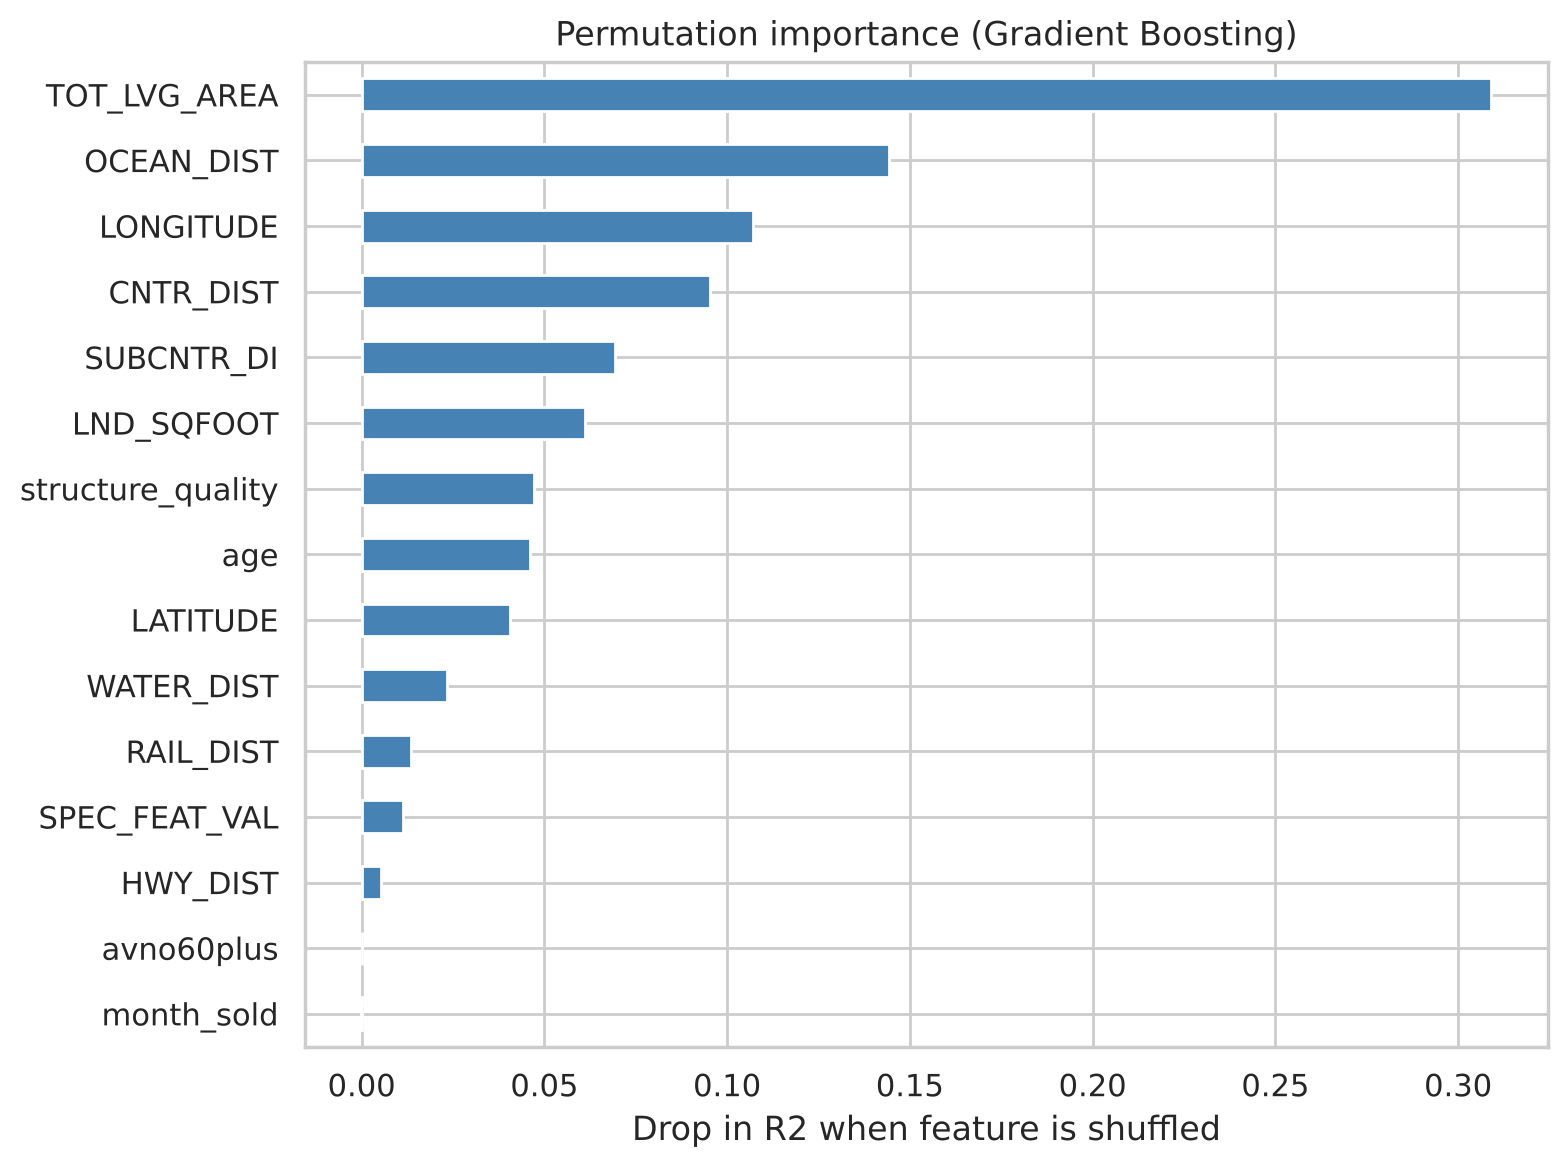

TOT_LVG_AREA         0.3091
OCEAN_DIST           0.1442
LONGITUDE            0.1071
CNTR_DIST            0.0952
SUBCNTR_DI           0.0692
LND_SQFOOT           0.0611
structure_quality    0.0473
age                  0.0461
dtype: float64

In [14]:
best_model = final_models[best_name]
perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=5,
    random_state=RANDOM_STATE, scoring="r2", n_jobs=1
)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
imp.plot(kind="barh", color="steelblue")
plt.xlabel("Drop in R2 when feature is shuffled")
plt.title(f"Permutation importance ({best_name})")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150)
plt.show()

imp.sort_values(ascending=False).round(4).head(8)

## 9. Takeaways and limitations

- Tree-based ensembles clearly outperform linear models, which suggests non-linear effects and interactions (especially location-related) matter.
- The most influential features are shown in the importance plot above.
- **Random split:** nearby houses can fall into both train and test sets, so test performance may be somewhat optimistic compared with predicting in a completely new area. A spatial or time-based split would be a stricter test.
- **Repeated parcels:** 13,776 unique parcels appear across 13,932 rows, so a few properties were sold more than once and can appear in both train and test. A group-aware split on `PARCELNO` would remove this overlap.
- **Target skew:** prices are right-skewed. Modeling `log(price)` is a natural next step.
- **Further work:** try XGBoost/LightGBM, more feature engineering, and SHAP for explanations.